# Nghiên cứu TF-IDF + Linear SVM trên ReINTEL


**Notebook 01 — bản đồng bộ với kết quả đã xác minh**

- **Bài toán:** phân loại văn bản mạng xã hội tiếng Việt thành `Reliable (0)` và `Unreliable (1)`.
- **Dữ liệu cuối:** **ReINTEL v2 Reviewed**, chia theo nhóm near-duplicate để hạn chế rò rỉ.
- **Mô hình cuối:** word TF-IDF `(1, 2)` + `LinearSVC(C=0.1, class_weight="balanced")`.
- **Nguồn sự thật:** artifact trong `reports/reintel_v2_reviewed/` và model đóng băng trong `models/reintel_v2_reviewed/`.
- **Nguyên tắc:** Test chỉ dùng một lần để báo cáo cuối; chọn feature và siêu tham số chỉ dựa trên Train/Validation hoặc group-aware CV.

Notebook vừa trình bày đầy đủ phương pháp, vừa chứa code kiểm tra artifact. Mỗi phần đều dẫn tới file thực thi liên quan trong `scripts/`.


In [15]:
from pathlib import Path
import hashlib
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

ROOT = next(
    (
        path for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "data").is_dir()
        and (path / "reports").is_dir()
        and (path / "scripts").is_dir()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Không tìm thấy thư mục gốc project.")

DATA_DIR = ROOT / "data/processed/reintel_v2_reviewed"
REPORT_DIR = ROOT / "reports/reintel_v2_reviewed"
FINAL_DIR = REPORT_DIR / "final"
MODEL_PATH = ROOT / "models/reintel_v2_reviewed/reintel_final.joblib"
LABEL_NAMES = {0: "Reliable", 1: "Unreliable"}

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:.4f}")

print("Project root:", ROOT)
print("Dataset:", DATA_DIR)
print("Reports:", REPORT_DIR)


Project root: /home/mujin/Code/Project/SvmUnreliableNewsDetection
Dataset: /home/mujin/Code/Project/SvmUnreliableNewsDetection/data/processed/reintel_v2_reviewed
Reports: /home/mujin/Code/Project/SvmUnreliableNewsDetection/reports/reintel_v2_reviewed


## 1. Introduction


### 1.1. Bối cảnh và phạm vi


ReINTEL chứa các bài đăng tiếng Việt được gán nhãn về độ tin cậy. Nghiên cứu kiểm tra một pipeline dễ tái lập: **TF-IDF** biến văn bản thành vector thưa, sau đó **Linear SVM** học siêu phẳng phân tách hai lớp.

Nhãn `Unreliable` là nhãn của bộ dữ liệu, không phải kết luận fact-check độc lập. Mô hình không truy xuất nguồn ngoài, không kiểm tra bằng chứng và có thể học dấu hiệu phong cách hoặc nguồn đăng thay vì tính đúng/sai của từng phát biểu.


### 1.2. Mục tiêu và câu hỏi nghiên cứu


1. Audit dữ liệu, xử lý văn bản lỗi và ngăn nhóm near-duplicate đi qua nhiều split.
2. So sánh word unigram, word bigram, word segmentation, character n-gram và word + character.
3. Chọn `C` và `class_weight` theo **Macro F1** bằng group-aware cross-validation.
4. Đánh giá một lần trên Test độc lập; phân tích lỗi, hệ số đặc trưng và learning curve.

- **RQ1:** biểu diễn TF-IDF nào tốt nhất trên Validation?
- **RQ2:** cấu hình SVM nào cân bằng tốt hai lớp theo group-aware CV?
- **RQ3:** mô hình cuối tổng quát tới Test như thế nào và còn hạn chế gì?

**Script nền tảng:** [`09_run_reintel_v2_experiments.py`](../scripts/01_reintel_experiments/09_run_reintel_v2_experiments.py), [`10_final_evaluate_reintel.py`](../scripts/01_reintel_experiments/10_final_evaluate_reintel.py).


## 2. Dataset Exploration


### 2.1. Nguồn dữ liệu và audit ban đầu


Nguồn gốc là Hugging Face `ReliableAI/ReINTEL`, split có nhãn `train`, gồm `post_message` và `label`. Log audit ban đầu ghi nhận **4.372 mẫu**: **3.638 Reliable** và **734 Unreliable**. Dữ liệu mất cân bằng rõ rệt, do đó Accuracy phải được đọc cùng Macro F1 và chỉ số lớp 1.

Audit thô phát hiện 1 văn bản thiếu/rỗng, 53 bản ghi chỉ chứa placeholder `<URL>`, duplicate hoàn toàn, near-duplicate và một số nhóm rất giống nhau nhưng nhãn không nhất quán.

- [`01_inspect_reintel.py`](../scripts/01_reintel_experiments/01_inspect_reintel.py): thống kê trực tiếp `post_message`.
- [`02_audit_reintel.py`](../scripts/01_reintel_experiments/02_audit_reintel.py): chuẩn hóa khoảng trắng thành `text`, rồi kiểm tra empty, URL-only, duplicate, xung đột nhãn và ngoại lệ độ dài.

Hai script dùng mức chuẩn hóa khác nhau nên số duplicate có thể khác nhau.

~~~bash
python scripts/01_reintel_experiments/01_inspect_reintel.py
python scripts/01_reintel_experiments/02_audit_reintel.py
~~~


In [16]:
# Đọc split Reviewed; không tải lại dữ liệu và không ghi file.
splits = {
    name: pd.read_csv(DATA_DIR / f"{name}.csv")
    for name in ["train", "val", "test"]
}
train, val, test = splits["train"], splits["val"], splits["test"]
dev = pd.concat([train, val], ignore_index=True)

dataset_summary = pd.DataFrame([
    {
        "split": name,
        "samples": len(frame),
        "reliable_0": int((frame["label"] == 0).sum()),
        "unreliable_1": int((frame["label"] == 1).sum()),
        "unreliable_rate": float((frame["label"] == 1).mean()),
        "groups": frame["group_id"].nunique(),
        "empty_text": int(frame["text"].fillna("").str.strip().eq("").sum()),
    }
    for name, frame in splits.items()
])
display(dataset_summary)

assert dataset_summary["samples"].tolist() == [3055, 608, 611]
assert dataset_summary["empty_text"].sum() == 0
assert set(dev["label"].unique()) == {0, 1}


,split,samples,reliable_0,unreliable_1,unreliable_rate,groups,empty_text
0,train,3055,2542,513,0.1679,3011,0
1,val,608,507,101,0.1661,598,0
2,test,611,508,103,0.1686,599,0


### 2.2. Snapshot đã xác minh


| Split | Số mẫu | Reliable | Unreliable | Nhóm độc lập |
|---|---:|---:|---:|---:|
| Train | 3.055 | 2.542 | 513 | 3.011 |
| Validation | 608 | 507 | 101 | 598 |
| Test | 611 | 508 | 103 | 599 |
| Development | 3.663 | 3.049 | 614 | — |

Tỷ lệ lớp 1 xấp xỉ 16,8% ở cả ba split. Code phía trên kiểm tra trực tiếp các con số từ CSV Reviewed.


## 3. Data Preprocessing


### 3.1. Quy trình tạo ReINTEL v2 Reviewed


1. [`03_prepare_reintel.py`](../scripts/01_reintel_experiments/03_prepare_reintel.py) chuẩn hóa khoảng trắng, bỏ empty/URL-only, loại exact duplicate và nhóm exact-text mâu thuẫn nhãn; tạo split v1.
2. [`04_audit_near_duplicates.py`](../scripts/01_reintel_experiments/04_audit_near_duplicates.py) dùng character TF-IDF `(3,5)` và cosine nearest-neighbor để audit near-duplicate giữa split v1.
3. [`05_review_near_duplicates.py`](../scripts/01_reintel_experiments/05_review_near_duplicates.py) xuất cặp similarity `>= 0.95` để xem thủ công.
4. [`06_prepare_reintel_v2.py`](../scripts/01_reintel_experiments/06_prepare_reintel_v2.py) gom mẫu similarity `>= 0.95` bằng Union-Find, gán `group_id`, rồi chia bằng `StratifiedGroupKFold`.
5. [`07_review_mixed_groups.py`](../scripts/01_reintel_experiments/07_review_mixed_groups.py) kiểm tra nhóm development có nhiều nhãn.
6. [`08_prepare_reintel_v2_reviewed.py`](../scripts/01_reintel_experiments/08_prepare_reintel_v2_reviewed.py) loại ba nhóm mâu thuẫn `{803, 946, 3758}` khỏi Train/Validation; Test được sao chép byte-for-byte.

Điểm quan trọng: **mọi mẫu thuộc cùng một nhóm near-duplicate chỉ nằm trong một split**.


In [17]:
excluded = pd.read_csv(DATA_DIR / "excluded_samples_audit.csv")
display(excluded)

group_sets = {name: set(frame["group_id"]) for name, frame in splits.items()}
overlap = pd.DataFrame([
    {"pair": "train-val", "overlapping_groups": len(group_sets["train"] & group_sets["val"])},
    {"pair": "train-test", "overlapping_groups": len(group_sets["train"] & group_sets["test"])},
    {"pair": "val-test", "overlapping_groups": len(group_sets["val"] & group_sets["test"])},
])
display(overlap)

assert set(excluded["group_id"]) == {803, 946, 3758}
assert len(excluded) == 7
assert overlap["overlapping_groups"].eq(0).all()
assert dev.groupby("group_id")["label"].nunique().max() == 1


,split,group_id,label,text_length
0,train,946,0,1241
1,train,946,1,1226
2,train,3758,0,4776
3,train,3758,1,4497
4,val,803,1,3582
5,val,803,1,3433
6,val,803,0,3648


,pair,overlapping_groups
0,train-val,0
1,train-test,0
2,val-test,0


In [18]:
with (FINAL_DIR / "test_metrics.json").open(encoding="utf-8") as file:
    final_metadata = json.load(file)

test_sha256 = hashlib.sha256((DATA_DIR / "test.csv").read_bytes()).hexdigest()
print("Current Test SHA256 :", test_sha256)
print("Recorded Test SHA256:", final_metadata["test_sha256"])
assert test_sha256 == final_metadata["test_sha256"]


Current Test SHA256 : 522776ee6302bd945c6a0e51d70df2de7e1a049adcf1316ae62ec781b7cf8c40
Recorded Test SHA256: 522776ee6302bd945c6a0e51d70df2de7e1a049adcf1316ae62ec781b7cf8c40


## 4. Feature Extraction


TF-IDF tăng trọng số cho n-gram xuất hiện nhiều trong một văn bản nhưng ít phổ biến trong corpus. Cấu hình dùng `lowercase=True`, `min_df=2`, `sublinear_tf=True`; character model giới hạn `max_features=100000`.

Sáu cấu hình trong [`09_run_reintel_v2_experiments.py`](../scripts/01_reintel_experiments/09_run_reintel_v2_experiments.py):

| ID | Đặc trưng | `class_weight` |
|---|---|---|
| M01 | word unigram | `None` |
| M02 | word unigram | `balanced` |
| M03 | word unigram–bigram | `balanced` |
| M04 | word bigram sau tách từ `underthesea` | `balanced` |
| M05 | character `char_wb (3,5)` | `balanced` |
| M06 | FeatureUnion word + character | `balanced` |

Audit trail v1: [`91_legacy_experiment_ngram.py`](../scripts/01_reintel_experiments/91_legacy_experiment_ngram.py), [`92_legacy_experiment_segmentation.py`](../scripts/01_reintel_experiments/92_legacy_experiment_segmentation.py), [`93_legacy_experiment_char_ngram.py`](../scripts/01_reintel_experiments/93_legacy_experiment_char_ngram.py).


,experiment,accuracy,macro_f1,precision_1,recall_1,f1_1,n_features
0,M03_word_bigram,0.9030,0.8136,0.7442,0.6337,0.6845,56628
1,M06_word_char,0.8964,0.8009,0.7209,0.6139,0.6631,116402
2,M05_char_wb,0.8799,0.7875,0.6321,0.6634,0.6473,59774
3,M01_word_unigram,0.8898,0.7698,0.7500,0.5050,0.6036,5202
4,M02_word_unigram_balanced,0.8651,0.7658,0.5856,0.6436,0.6132,5202
5,M04_word_segmented,0.8799,0.7631,0.6750,0.5347,0.5967,51539


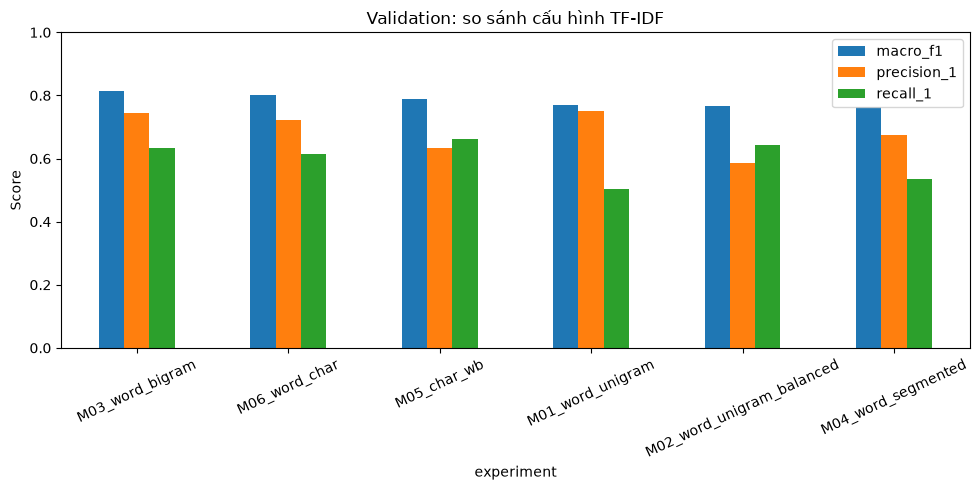

In [19]:
feature_results = pd.read_csv(REPORT_DIR / "fixed_experiments.csv")
feature_view = feature_results[
    ["experiment", "accuracy", "macro_f1", "precision_1", "recall_1", "f1_1", "n_features"]
].sort_values("macro_f1", ascending=False)
display(feature_view.reset_index(drop=True))

best_feature = feature_view.iloc[0]
assert best_feature["experiment"] == "M03_word_bigram"
assert np.isclose(best_feature["macro_f1"], 0.8135773790035494)

ax = feature_view.set_index("experiment")[["macro_f1", "precision_1", "recall_1"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1), rot=25,
    title="Validation: so sánh cấu hình TF-IDF",
)
ax.set_ylabel("Score")
plt.tight_layout()
plt.show()


### 4.1. Kết quả feature đã xác minh


| Cấu hình | Accuracy | Macro F1 | Precision lớp 1 | Recall lớp 1 |
|---|---:|---:|---:|---:|
| M03 word bigram | **0,9030** | **0,8136** | 0,7442 | 0,6337 |
| M06 word + char | 0,8964 | 0,8009 | 0,7209 | 0,6139 |
| M05 char | 0,8799 | 0,7875 | 0,6321 | **0,6634** |
| M01 word unigram | 0,8898 | 0,7698 | **0,7500** | 0,5050 |
| M02 unigram balanced | 0,8651 | 0,7658 | 0,5856 | 0,6436 |
| M04 segmented | 0,8799 | 0,7631 | 0,6750 | 0,5347 |

**RQ1:** M03 có Macro F1 Validation cao nhất. Character n-gram tăng Recall lớp 1 nhưng không vượt word bigram về Macro F1. Tách từ không cải thiện trong thiết lập này.


## 5. Model Training


Pipeline cuối:

~~~python
Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="word", ngram_range=(1, 2),
        lowercase=True, min_df=2, sublinear_tf=True,
    )),
    ("svm", LinearSVC(
        C=0.1, class_weight="balanced",
        random_state=42, max_iter=5000,
    )),
])
~~~

Sau khi chọn siêu tham số mà không xem Test, [`10_final_evaluate_reintel.py`](../scripts/01_reintel_experiments/10_final_evaluate_reintel.py) refit trên **Train + Validation = 3.663 mẫu**. Model đóng băng: `models/reintel_v2_reviewed/reintel_final.joblib`.


In [20]:
if not MODEL_PATH.is_file():
    raise FileNotFoundError(f"Thiếu model cuối: {MODEL_PATH}")

final_model = joblib.load(MODEL_PATH)
tfidf = final_model.named_steps["tfidf"]
svm = final_model.named_steps["svm"]

model_config = pd.Series({
    "analyzer": tfidf.analyzer,
    "ngram_range": tfidf.ngram_range,
    "lowercase": tfidf.lowercase,
    "min_df": tfidf.min_df,
    "sublinear_tf": tfidf.sublinear_tf,
    "vocabulary_size": len(tfidf.vocabulary_),
    "C": svm.C,
    "class_weight": svm.class_weight,
    "max_iter": svm.max_iter,
    "development_samples": len(dev),
})
display(model_config.to_frame("value"))

assert tfidf.ngram_range == (1, 2)
assert svm.C == 0.1 and svm.class_weight == "balanced"
assert len(dev) == 3663


,value
analyzer,word
ngram_range,"(1, 2)"
lowercase,True
min_df,2
sublinear_tf,True
vocabulary_size,64964
C,0.1000
class_weight,balanced
max_iter,5000
development_samples,3663


## 6. Hyperparameter Tuning


[`09_run_reintel_v2_experiments.py`](../scripts/01_reintel_experiments/09_run_reintel_v2_experiments.py) dùng `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` trên Train và truyền `group_id` vào GridSearchCV.

- `C ∈ {0.01, 0.1, 1, 10, 100}`.
- `class_weight ∈ {None, "balanced"}`.
- Metric refit: **Macro F1**.

Group-aware CV ngăn một nhóm near-duplicate xuất hiện ở cả train fold và validation fold. [`94_legacy_experiment_svm_tuning.py`](../scripts/01_reintel_experiments/94_legacy_experiment_svm_tuning.py) là phiên bản v1 dùng StratifiedKFold, không phải nguồn model cuối.


In [21]:
tuning = pd.read_csv(REPORT_DIR / "svm_tuning_cv.csv")
tuning_view = tuning[
    [
        "param_svm__C", "param_svm__class_weight",
        "mean_test_macro_f1", "std_test_macro_f1",
        "mean_test_precision_1", "mean_test_recall_1",
        "mean_train_macro_f1", "rank_test_macro_f1",
    ]
].sort_values(["rank_test_macro_f1", "param_svm__C"])
display(tuning_view.reset_index(drop=True))

best_cv = tuning.sort_values("rank_test_macro_f1").iloc[0]
tuned_validation = pd.read_csv(REPORT_DIR / "tuned_validation.csv")
display(tuned_validation)

assert best_cv["param_svm__C"] == 0.1
assert best_cv["param_svm__class_weight"] == "balanced"
assert np.isclose(best_cv["mean_test_macro_f1"], 0.7684122572358445)


,param_svm__C,param_svm__class_weight,mean_test_macro_f1,std_test_macro_f1,mean_test_precision_1,mean_test_recall_1,mean_train_macro_f1,rank_test_macro_f1
0,0.1000,balanced,0.7684,0.0281,0.5895,0.6531,0.9410,1
1,1.0000,balanced,0.7679,0.0260,0.6899,0.5400,0.9990,2
2,10.0000,balanced,0.7436,0.0271,0.7113,0.4600,0.9991,3
3,100.0000,NaN,0.7426,0.0250,0.7185,0.4541,0.9996,4
4,100.0000,balanced,0.7426,0.0250,0.7185,0.4541,0.9996,4
5,10.0000,NaN,0.7410,0.0287,0.7255,0.4463,0.9996,6
6,0.0100,balanced,0.7365,0.0286,0.5022,0.6823,0.8499,7
7,1.0000,NaN,0.7148,0.0302,0.7665,0.3722,0.9993,8
8,0.1000,NaN,0.5325,0.0200,0.9500,0.0819,0.6203,9
9,0.0100,NaN,0.4542,0.0002,0.0000,0.0000,0.4542,10


,accuracy,macro_f1,precision_1,recall_1,f1_1
0,0.8931,0.8150,0.6607,0.7327,0.6948


### 6.1. Kết luận tuning


`C=0.1, class_weight="balanced"` đạt CV Macro F1 **0,7684 ± 0,0281**. Trên Validation độc lập, estimator đạt Macro F1 **0,8150** và Recall lớp 1 **0,7327**.

`C=1.0, balanced` có CV Macro F1 gần tương đương (**0,7679**) nhưng train Macro F1 **0,9990**, trong khi `C=0.1` có **0,9410**. Chọn `C=0.1` vừa đúng hạng CV, vừa regularize mạnh hơn.

**RQ2:** class weighting tăng độ nhạy với lớp thiểu số; `C=0.1, balanced` cân bằng tốt nhất theo tiêu chí định trước.


## 7. Model Evaluation


[`10_final_evaluate_reintel.py`](../scripts/01_reintel_experiments/10_final_evaluate_reintel.py) đánh giá cuối đúng một lần. Script có guard không ghi đè `test_metrics.json`, kiểm tra kích thước dữ liệu, cô lập group, lưu prediction và SHA256 của Test.

- **Accuracy:** tỷ lệ dự đoán đúng tổng thể.
- **Macro F1:** trung bình F1 của hai lớp với trọng số ngang nhau.
- **Precision lớp 1:** trong các mẫu dự đoán Unreliable, tỷ lệ đúng.
- **Recall lớp 1:** trong các mẫu Unreliable thật, tỷ lệ được phát hiện.
- Với nhãn `[0, 1]`, confusion matrix là `[[TN, FP], [FN, TP]]`.


,recorded,recomputed,absolute_difference
accuracy,0.8642,0.8642,0.0000
macro_f1,0.7708,0.7708,0.0000
precision_1,0.5847,0.5847,0.0000
recall_1,0.6699,0.6699,0.0000
f1_1,0.6244,0.6244,0.0000
tn,459.0000,459.0000,0.0000
fp,49.0000,49.0000,0.0000
fn,34.0000,34.0000,0.0000
tp,69.0000,69.0000,0.0000


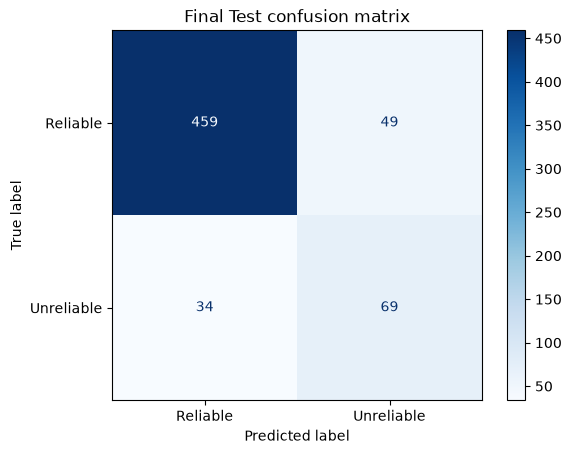

In [22]:
predictions = pd.read_csv(FINAL_DIR / "test_predictions.csv")
assert len(predictions) == len(test) == final_metadata["test_samples"]
assert np.array_equal(predictions["actual_label"].to_numpy(), test["label"].to_numpy())

y_true = predictions["actual_label"]
y_pred = predictions["predicted_label"]
tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

recomputed = {
    "accuracy": accuracy_score(y_true, y_pred),
    "macro_f1": f1_score(y_true, y_pred, average="macro"),
    "precision_1": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
    "recall_1": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
    "f1_1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
}
comparison = pd.DataFrame({"recorded": final_metadata["metrics"], "recomputed": recomputed})
comparison["absolute_difference"] = (
    comparison["recorded"].astype(float) - comparison["recomputed"].astype(float)
).abs()
display(comparison)
assert comparison["absolute_difference"].max() < 1e-12

ConfusionMatrixDisplay(
    np.array([[tn, fp], [fn, tp]]), display_labels=["Reliable", "Unreliable"]
).plot(cmap="Blues")
plt.title("Final Test confusion matrix")
plt.show()


### 7.1. Final Test — snapshot đã xác minh


| Metric | Giá trị |
|---|---:|
| Accuracy | **0,8642** |
| Macro F1 | **0,7708** |
| Precision — Unreliable | **0,5847** |
| Recall — Unreliable | **0,6699** |
| F1 — Unreliable | **0,6244** |
| TN / FP / FN / TP | **459 / 49 / 34 / 69** |

Trong 611 mẫu Test có 83 lỗi. Model phát hiện 69/103 mẫu Unreliable, nhưng 49 mẫu Reliable bị gắn nhãn Unreliable. Accuracy cao hơn Macro F1 vì lớp Reliable chiếm đa số.


## 8. Error Analysis


- **False Positive:** Reliable bị dự đoán Unreliable; làm giảm Precision lớp 1.
- **False Negative:** Unreliable bị dự đoán Reliable; làm giảm Recall lớp 1.

Phân tích chỉ đọc prediction đóng băng và nối văn bản theo `sample_index`; không dùng để tinh chỉnh model. [`95_legacy_analyze_errors.py`](../scripts/01_reintel_experiments/95_legacy_analyze_errors.py) là bản Validation v1; notebook tái dựng Final Test từ `final/test_predictions.csv`.


In [23]:
errors = predictions.loc[y_true.ne(y_pred)].copy()
errors["error_type"] = np.where(
    errors["actual_label"].eq(0), "False Positive", "False Negative"
)
errors["text"] = test.loc[errors["sample_index"], "text"].fillna("").to_numpy()
errors["text_length"] = errors["text"].str.len()

error_summary = errors.groupby("error_type").agg(
    count=("sample_index", "size"),
    mean_length=("text_length", "mean"),
    median_length=("text_length", "median"),
    min_length=("text_length", "min"),
    max_length=("text_length", "max"),
)
display(error_summary)

assert len(errors) == 83
assert error_summary.loc["False Positive", "count"] == 49
assert error_summary.loc["False Negative", "count"] == 34

examples = errors.groupby("error_type", group_keys=False).head(3).copy()
examples["text_preview"] = examples["text"].str.slice(0, 180)
display(examples[["sample_index", "error_type", "text_length", "text_preview"]])


,count,mean_length,median_length,min_length,max_length
error_type,,,,,
False Negative,34,329.1176,176.0000,44,2531
False Positive,49,1339.4694,414.0000,74,10867


,sample_index,error_type,text_length,text_preview
2,2,False Positive,220,"Nam Định: Thảm sát trong đêm, 8 người trong mộ..."
21,21,False Positive,1657,Cảnh sát trưởng New York Terence Monahan quỳ g...
24,24,False Positive,247,Dâm ô con gái 8 tuổi bị tự kỉ của người cứu mạ...
29,29,False Negative,52,Vừa nghe tin Đà Lạt có 2 du khách bị nhiễm COV...
33,33,False Negative,181,Ngày đầu tiên của Đại hội Y tế thế giới: Nga v...
60,60,False Negative,166,Sài Gòn cũng đã có một khu vực bị cách ly ở đư...


### 8.1. Diễn giải


False Positive nhiều hơn False Negative (49 so với 34), phù hợp với đánh đổi của `class_weight="balanced"`: model phát hiện lớp thiểu số tốt hơn nhưng tạo thêm cảnh báo sai. Review vài mẫu chỉ dùng để hình thành giả thuyết, không phải quy luật tổng quát.

Hướng tiếp theo: phân tầng theo độ dài/chủ đề, kiểm thử ngoài phân phối và đánh giá con người. Không quay lại tối ưu trên Test hiện tại.


## 9. Model Interpretability


Với LinearSVC nhị phân, hệ số dương đẩy quyết định về `1 — Unreliable`, hệ số âm đẩy về `0 — Reliable`. Độ lớn tuyệt đối cho biết tác động trong không gian TF-IDF, nhưng **không chứng minh quan hệ nhân quả** và có thể phản ánh nguồn, chủ đề hoặc phong cách dataset.

Code đọc trực tiếp vocabulary và `coef_` của model cuối; không huấn luyện lại.


,feature,coefficient
0,url,-1.3677
1,covid 19,-0.7368
2,url url,-0.7349
3,19,-0.6958
4,covid,-0.5540
5,việc,-0.5410
6,hà,-0.5340
7,định,-0.5172
8,dịch covid,-0.4984
9,dự,-0.4765


,feature,coefficient
0,thì,1.2382
1,corona,1.0567
2,rồi,1.0269
3,này,0.9032
4,ko,0.8929
5,chết,0.8684
6,mà,0.8496
7,trung quốc,0.8381
8,bị,0.8208
9,vn,0.8069


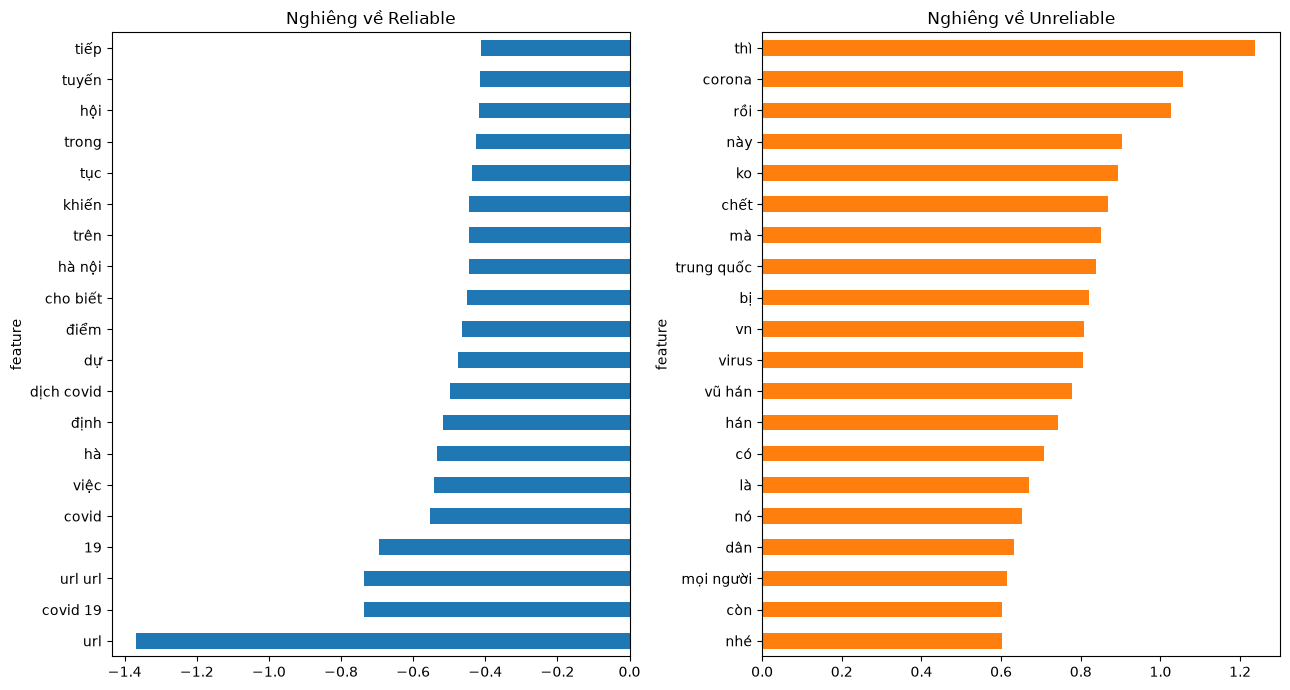

In [24]:
feature_names = tfidf.get_feature_names_out()
weights = svm.coef_.ravel()

top_reliable = pd.DataFrame({
    "feature": feature_names[np.argsort(weights)[:20]],
    "coefficient": np.sort(weights)[:20],
})
top_unreliable_idx = np.argsort(weights)[-20:][::-1]
top_unreliable = pd.DataFrame({
    "feature": feature_names[top_unreliable_idx],
    "coefficient": weights[top_unreliable_idx],
})
display(top_reliable)
display(top_unreliable)

fig, axes = plt.subplots(1, 2, figsize=(13, 7))
top_reliable.sort_values("coefficient").plot.barh(
    x="feature", y="coefficient", ax=axes[0], legend=False, title="Nghiêng về Reliable"
)
top_unreliable.sort_values("coefficient").plot.barh(
    x="feature", y="coefficient", ax=axes[1], legend=False,
    color="tab:orange", title="Nghiêng về Unreliable"
)
plt.tight_layout()
plt.show()


## 10. Additional Experiments — Learning Curve


[`11_learning_curve_reintel.py`](../scripts/01_reintel_experiments/11_learning_curve_reintel.py) dùng cấu hình cuối, toàn bộ Development và 5-fold `StratifiedGroupKFold`. Final Test không được truy cập. Mỗi điểm báo cáo trung bình và độ lệch chuẩn Macro F1 qua năm fold.


,train_size,train_macro_f1_mean,train_macro_f1_std,cv_macro_f1_mean,cv_macro_f1_std,generalization_gap
0,586,0.9756,0.0086,0.7486,0.0029,0.2270
1,1172,0.9568,0.0059,0.7709,0.0083,0.1859
2,1758,0.9474,0.0042,0.7789,0.0121,0.1686
3,2344,0.9408,0.0035,0.7801,0.0106,0.1607
4,2930,0.9390,0.0029,0.7817,0.0118,0.1573


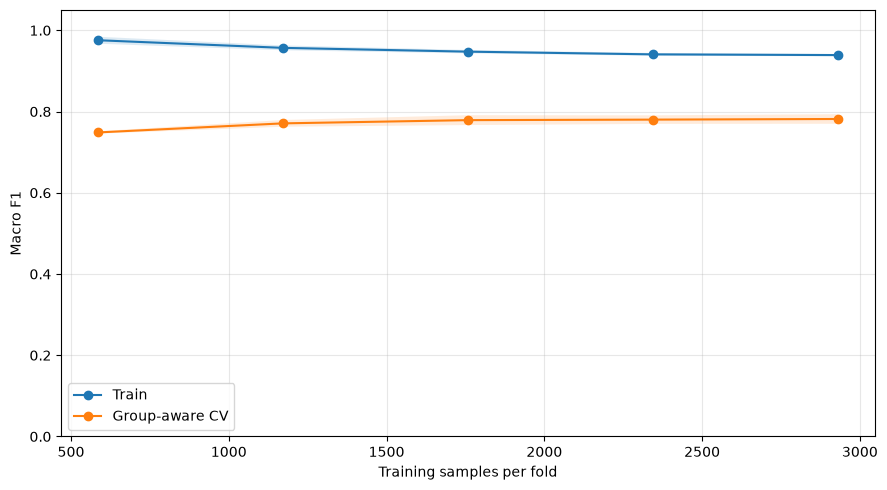

CV Macro F1 cuối: 0.7817 ± 0.0118
Generalization gap cuối: 0.1573


In [25]:
curve = pd.read_csv(REPORT_DIR / "learning_curve/learning_curve.csv")
display(curve)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(curve["train_size"], curve["train_macro_f1_mean"], marker="o", label="Train")
ax.fill_between(
    curve["train_size"],
    curve["train_macro_f1_mean"] - curve["train_macro_f1_std"],
    curve["train_macro_f1_mean"] + curve["train_macro_f1_std"],
    alpha=0.15,
)
ax.plot(curve["train_size"], curve["cv_macro_f1_mean"], marker="o", label="Group-aware CV")
ax.fill_between(
    curve["train_size"],
    curve["cv_macro_f1_mean"] - curve["cv_macro_f1_std"],
    curve["cv_macro_f1_mean"] + curve["cv_macro_f1_std"],
    alpha=0.15,
)
ax.set(xlabel="Training samples per fold", ylabel="Macro F1", ylim=(0, 1.05))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(
    "CV Macro F1 cuối:",
    f'{curve.iloc[-1]["cv_macro_f1_mean"]:.4f} ± {curve.iloc[-1]["cv_macro_f1_std"]:.4f}',
)
print("Generalization gap cuối:", f'{curve.iloc[-1]["generalization_gap"]:.4f}')


### 10.1. Kết quả learning curve


CV Macro F1 tăng từ **0,7486** ở 586 mẫu/fold lên **0,7817 ± 0,0118** ở 2.930 mẫu/fold. Generalization gap giảm từ **0,2270** xuống **0,1573**, nhưng chưa biến mất. Thêm dữ liệu đa dạng có thể còn hữu ích; pipeline vẫn có xu hướng overfit tín hiệu từ vựng.


## 11. Discussion


### 11.1. Trả lời câu hỏi nghiên cứu


- **RQ1:** word TF-IDF unigram–bigram (M03) tốt nhất trên Validation, Macro F1 **0,8136**.
- **RQ2:** group-aware CV chọn `C=0.1, class_weight="balanced"`, CV Macro F1 **0,7684 ± 0,0281**.
- **RQ3:** model cuối đạt Test Accuracy **0,8642**, Macro F1 **0,7708**, F1 lớp Unreliable **0,6244**; còn 49 FP và 34 FN.


### 11.2. Threats to validity


1. Nhãn có thể chứa nhiễu; near-duplicate mixed-label là bằng chứng trực tiếp.
2. Ngưỡng cosine 0,95 giảm rò rỉ nhưng không bắt được mọi paraphrase.
3. Validation feature comparison và CV tuning là hai giao thức khác nhau.
4. Hệ số SVM giải thích model, không giải thích tính đúng/sai thực tế.
5. Test cùng nguồn dữ liệu, chưa chứng minh khả năng chuyển miền.


### 11.3. Kết luận


TF-IDF + Linear SVM là baseline nhanh, minh bạch và khá mạnh cho ReINTEL, nhưng chưa đủ làm hệ thống fact-check. Bước tiếp theo nên ưu tiên dữ liệu ngoài phân phối, kiểm tra source bias, ngữ cảnh và đánh giá con người.


## Phụ lục A — Bản đồ notebook ↔ scripts ↔ artifacts


| Phần | Script chính | Artifact notebook đọc |
|---|---|---|
| Dataset exploration | [`01_inspect_reintel.py`](../scripts/01_reintel_experiments/01_inspect_reintel.py), [`02_audit_reintel.py`](../scripts/01_reintel_experiments/02_audit_reintel.py) | CSV Reviewed |
| Preprocessing v1 | [`03_prepare_reintel.py`](../scripts/01_reintel_experiments/03_prepare_reintel.py) | `data/processed/reintel/*.csv` |
| Near-duplicate audit | [`04_audit_near_duplicates.py`](../scripts/01_reintel_experiments/04_audit_near_duplicates.py), [`05_review_near_duplicates.py`](../scripts/01_reintel_experiments/05_review_near_duplicates.py) | `reports/near_duplicate_*.csv` |
| Group-aware split | [`06_prepare_reintel_v2.py`](../scripts/01_reintel_experiments/06_prepare_reintel_v2.py) | `data/processed/reintel_v2/*.csv` |
| Mixed-label review | [`07_review_mixed_groups.py`](../scripts/01_reintel_experiments/07_review_mixed_groups.py) | `reintel_v2_mixed_groups_review.csv` |
| Reviewed dataset | [`08_prepare_reintel_v2_reviewed.py`](../scripts/01_reintel_experiments/08_prepare_reintel_v2_reviewed.py) | `reintel_v2_reviewed/*.csv` |
| Feature + tuning | [`09_run_reintel_v2_experiments.py`](../scripts/01_reintel_experiments/09_run_reintel_v2_experiments.py) | `fixed_experiments.csv`, `svm_tuning_cv.csv` |
| Final Test | [`10_final_evaluate_reintel.py`](../scripts/01_reintel_experiments/10_final_evaluate_reintel.py) | `test_metrics.json`, `test_predictions.csv`, final model |
| Error analysis | notebook; [`95_legacy_analyze_errors.py`](../scripts/01_reintel_experiments/95_legacy_analyze_errors.py) là v1 | prediction artifact |
| Interpretability | notebook đọc model cuối | `reintel_final.joblib` |
| Learning curve | [`11_learning_curve_reintel.py`](../scripts/01_reintel_experiments/11_learning_curve_reintel.py) | `learning_curve.csv`, `learning_curve.png` |

~~~bash
python scripts/01_reintel_experiments/01_inspect_reintel.py
python scripts/01_reintel_experiments/02_audit_reintel.py
python scripts/01_reintel_experiments/03_prepare_reintel.py
python scripts/01_reintel_experiments/04_audit_near_duplicates.py
python scripts/01_reintel_experiments/05_review_near_duplicates.py
python scripts/01_reintel_experiments/06_prepare_reintel_v2.py
python scripts/01_reintel_experiments/07_review_mixed_groups.py
python scripts/01_reintel_experiments/08_prepare_reintel_v2_reviewed.py
python scripts/01_reintel_experiments/09_run_reintel_v2_experiments.py
# Chỉ chạy bước Final Test khi chưa có test_metrics.json:
python scripts/01_reintel_experiments/10_final_evaluate_reintel.py
python scripts/01_reintel_experiments/11_learning_curve_reintel.py
~~~

> `10_final_evaluate_reintel.py` cố ý dừng nếu kết quả Test đã tồn tại để tránh ghi đè hoặc tuning ngầm trên Test.


## Phụ lục B — Kiểm tra đồng bộ tự động


In [26]:
expected = {
    "development_samples": 3663,
    "test_samples": 611,
    "test_macro_f1": 0.7707586531115943,
    "test_accuracy": 0.8641571194762684,
    "best_feature": "M03_word_bigram",
    "best_C": 0.1,
    "best_class_weight": "balanced",
}
checks = {
    "development sample count": len(dev) == expected["development_samples"],
    "test sample count": len(test) == expected["test_samples"],
    "test checksum": test_sha256 == final_metadata["test_sha256"],
    "recorded vs recomputed metrics": comparison["absolute_difference"].max() < 1e-12,
    "test Macro F1": np.isclose(recomputed["macro_f1"], expected["test_macro_f1"]),
    "test Accuracy": np.isclose(recomputed["accuracy"], expected["test_accuracy"]),
    "best feature": best_feature["experiment"] == expected["best_feature"],
    "best C": best_cv["param_svm__C"] == expected["best_C"],
    "best class weight": best_cv["param_svm__class_weight"] == expected["best_class_weight"],
    "no split group overlap": overlap["overlapping_groups"].eq(0).all(),
}
check_table = pd.Series(checks, name="passed").to_frame()
display(check_table)
assert check_table["passed"].all()
print("OK — toàn bộ kết quả chính đã đồng bộ với artifact ReINTEL v2 Reviewed.")


,passed
development sample count,True
test sample count,True
test checksum,True
recorded vs recomputed metrics,True
test Macro F1,True
test Accuracy,True
best feature,True
best C,True
best class weight,True
no split group overlap,True


OK — toàn bộ kết quả chính đã đồng bộ với artifact ReINTEL v2 Reviewed.
